In [2]:
# libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [3]:
X = pd.read_csv('../data/processed/reviews_scaled.csv')

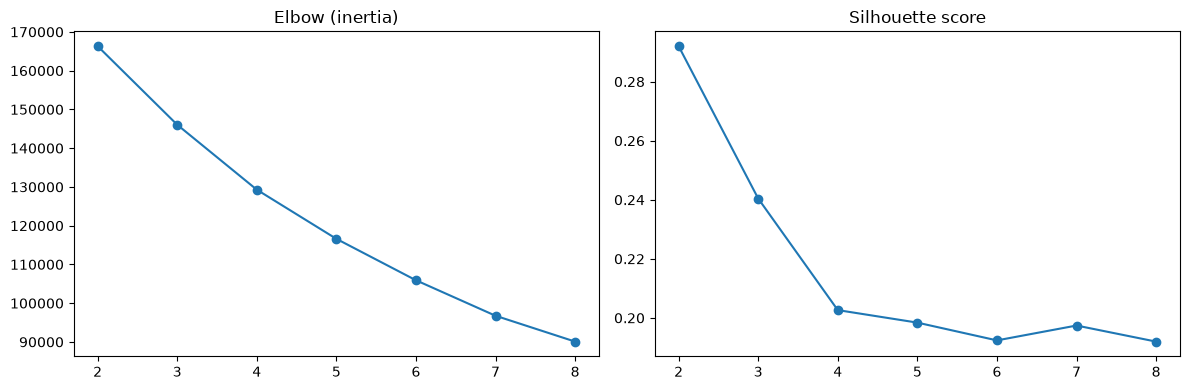

In [4]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=10000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, marker='o'); ax[0].set_title('Elbow (inertia)')
ax[1].plot(ks, sil, marker='o');     ax[1].set_title('Silhouette score')
plt.tight_layout(); plt.show()

In [7]:
km = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X)

enc = pd.read_csv('../data/processed/reviews_encoded.csv')
enc['cluster'] = km.labels_

profile = enc.groupby('cluster').agg(
    size=('rating', 'size'),
    avg_price=('price_usd', 'mean'),
    avg_spec=('avg_spec_score', 'mean'),
    avg_rating=('rating', 'mean'),
    avg_votes=('helpful_votes', 'mean'),
    avg_age=('age', 'mean')).round(2)

print(profile)
print(enc.groupby('cluster')[[c for c in enc.columns if c.startswith('brand_')]].mean().round(2))

          size  avg_price  avg_spec  avg_rating  avg_votes  avg_age
cluster                                                            
0        15428     505.73      1.72        1.97       2.09    29.24
1        14680     679.94      3.61        4.11       5.32    23.85
2         8789    1083.46      1.96        2.27       2.44    30.08
3        11103     646.53      3.52        4.01       4.55    39.47
         brand_Apple  brand_Google  brand_Motorola  brand_Oneplus  \
cluster                                                             
0               0.03          0.10            0.21           0.15   
1               0.13          0.15            0.14           0.15   
2               0.40          0.20            0.01           0.11   
3               0.11          0.15            0.15           0.15   

         brand_Realme  brand_Samsung  brand_Xiaomi  
cluster                                             
0                0.21           0.09          0.22  
1                0

In [9]:
import joblib

In [10]:
names = {0: 'Budget - Dissatisfied', 1: 'Mid-range - Young Enthusiasts',
         2: 'Premium - Dissatisfied', 3: 'Mid-range - Mature Satisfied'}
enc['segment'] = enc['cluster'].map(names)

enc.to_csv('../data/processed/reviews_clustered.csv', index=False)
joblib.dump(km, '../models/kmeans_k4.pkl')

enc['segment'].value_counts()

segment
Budget - Dissatisfied            15428
Mid-range - Young Enthusiasts    14680
Mid-range - Mature Satisfied     11103
Premium - Dissatisfied            8789
Name: count, dtype: int64

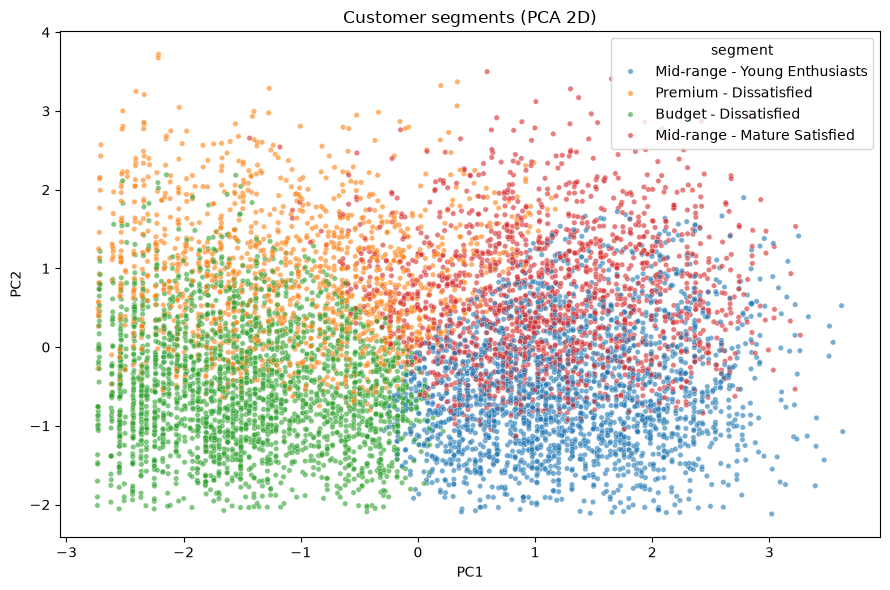

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 2D scatter using PCA
pts = PCA(n_components=2, random_state=42).fit_transform(X)
plot_df = pd.DataFrame(pts, columns=['PC1', 'PC2'])
plot_df['segment'] = enc['segment']

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df.sample(8000, random_state=42), x='PC1', y='PC2',
                hue='segment', alpha=0.6, s=15)
plt.title('Customer segments (PCA 2D)')
plt.tight_layout(); plt.show()

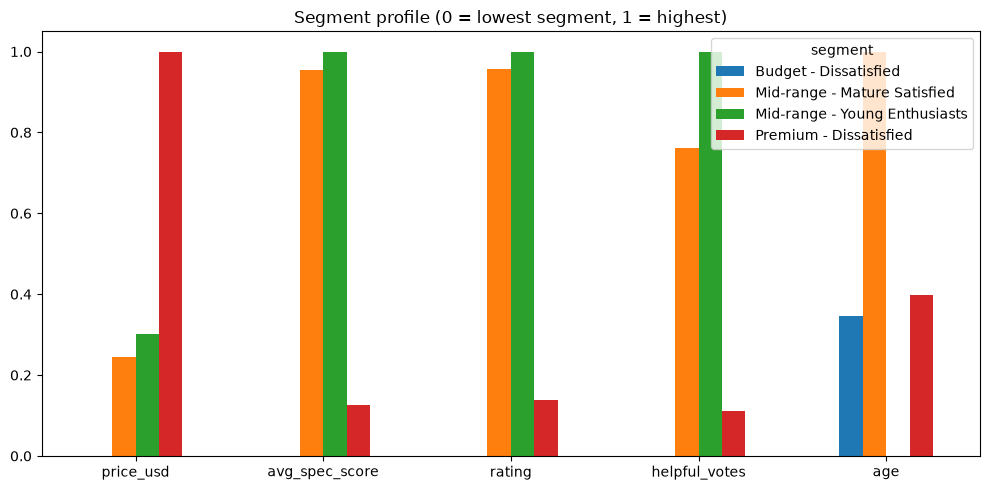

In [16]:
# segment profile (each feature scaled 0-1 so they fit one chart)
feats = ['price_usd', 'avg_spec_score', 'rating', 'helpful_votes', 'age']
prof = enc.groupby('segment')[feats].mean()
prof_norm = (prof - prof.min()) / (prof.max() - prof.min())

prof_norm.T.plot(kind='bar', figsize=(10, 5))
plt.title('Segment profile (0 = lowest segment, 1 = highest)')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

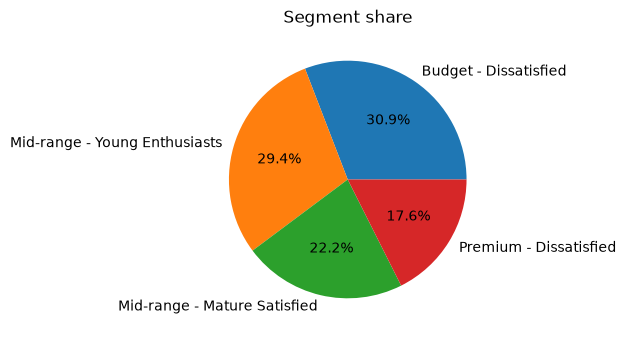

In [17]:
# segment size
enc['segment'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6))
plt.title('Segment share'); plt.ylabel('')
plt.tight_layout(); plt.show()